In [1]:
import os
import glob
import os
import pandas as pd
import numpy as np
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
from tqdm import tqdm
import time
from scipy.spatial.distance import cdist
import scipy
from scanpy.tools._utils import get_init_pos_from_paga 

import rmm
import cupy
import cudf
import cupy as cp
# import cvxpy as cpv
from cuml.metrics import pairwise_distances
from cuml.metrics import nan_euclidean_distances
from rmm.allocators.cupy import rmm_cupy_allocator
import anndata as an
import scanpy as sc
import rapids_singlecell as rsc
import scvi
import matplotlib.ticker as ticker
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap

# Enable `managed_memory`
rmm.reinitialize(
    managed_memory=True,
    pool_allocator=False,
)
cp.cuda.set_allocator(rmm_cupy_allocator)

# Load in data

In [2]:
%%time
# h5ad built in Hematokytos/figure4/QC_bone_marrow.ipynb
fpath = "/nfs/turbo/umms-indikar/shared/projects/HSC/pipeline_outputs/integrated_anndata/bone_marrow_processed.h5ad"

adata = sc.read_h5ad(fpath)
adata

CPU times: user 384 ms, sys: 982 ms, total: 1.37 s
Wall time: 3.16 s


AnnData object with n_obs × n_vars = 5608 × 22954
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_counts', 'n_genes', 'leiden', 'bm_cluster', 'CD34_avg', 'CD164_avg', 'PROM1_avg', 'CD48_avg', 'FLT3_avg', 'MPO_avg', 'IRF8_avg', 'CD79A_avg', 'GATA1_avg', 'CD34pos_CD38neg_B0251_HTO_1', 'CD34pos_CD38pos_B0252_HTO_2', 'HTO_pred', 'HTO_pred_label', 'cluster_preds', 'CD164_mean', 'CD34_mean', 'CD38_mean', 'THY1_mean', 'PTPRC_mean', 'MME_mean', 'CD7_mean', 'FLT3_mean', 'PLEK_mean', 'BST2_mean', 'CD37_mean', 'KIT_mean', 'ICAM3_mean', 'CD44_mean', 'EVI2B_mean', 'CD63_mean', 'ITGA2B_mean', 'CSF2RB_mean', 'PROM1_mean', 'ATP1B3_mean',

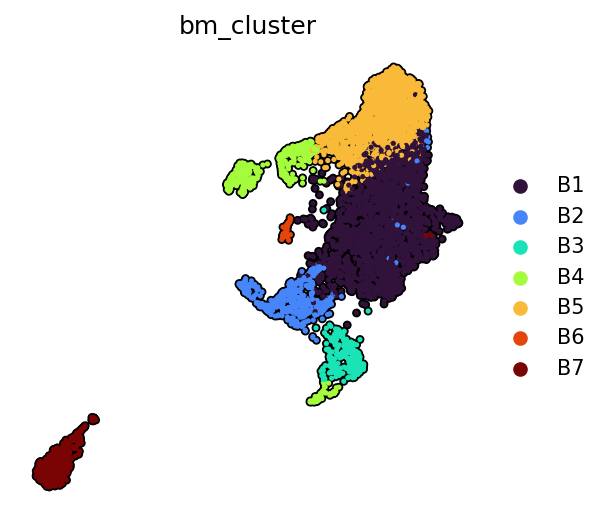

In [3]:
plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = 4, 4

sc.pl.umap(
    adata,
    color='bm_cluster',
    palette='turbo',
    size=25,
    ncols=3,
    alpha=1,
    use_raw=False,
    add_outline=True,
    outline_color=('k', 'k'),
    frameon=False,
    wspace=0.5,
)

# Recluster

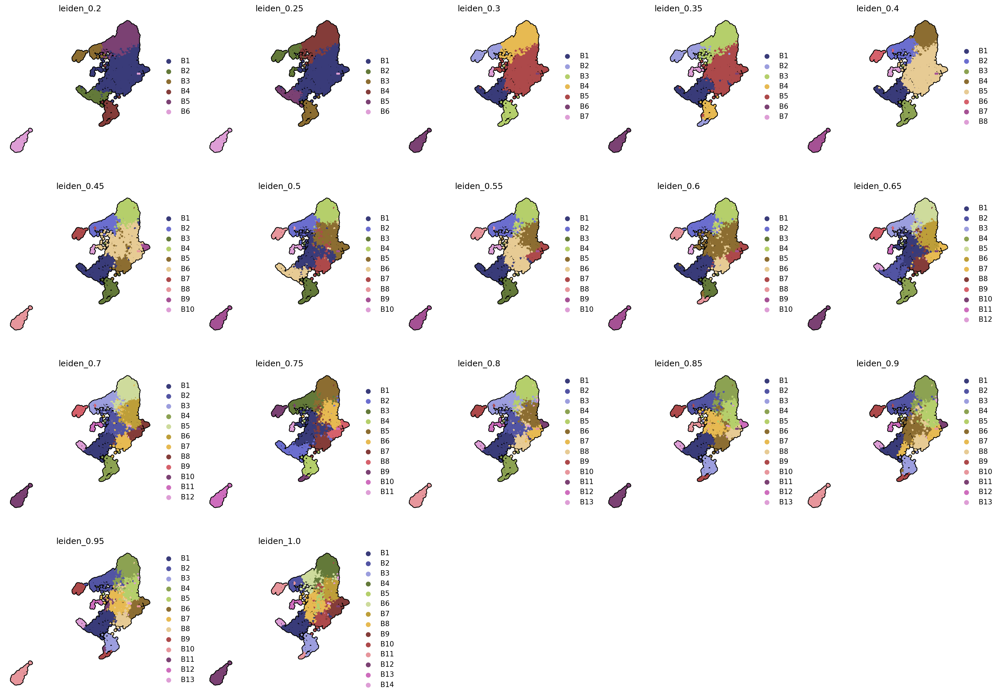

In [26]:
rng = 1729
np.random.seed(rng)


cluster_res = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]

# cluster_res = [0.2, 0.3]

for res in cluster_res:

    sc.tl.leiden(
        adata,
        resolution=res,
        random_state=rng,
        key_added=f'leiden_{res}',
        flavor='igraph',
    )

    adata.obs[f'leiden_{res}'] = adata.obs[f'leiden_{res}'].apply(lambda x: f"B{int(x) + 1}")
    
    
plot_cols = [col for col in adata.obs.columns if 'leiden_' in col]
plot_cols = sorted(plot_cols)

sc.pl.umap(
    adata,
    color=plot_cols,
    size=40,
    palette='tab20b',
    ncols=5,
    alpha=1,
    use_raw=False,
    # layer='log_norm',
    add_outline=True,
    outline_color=('k', 'k'),
    frameon=False,
    # wspace=0.5,
)

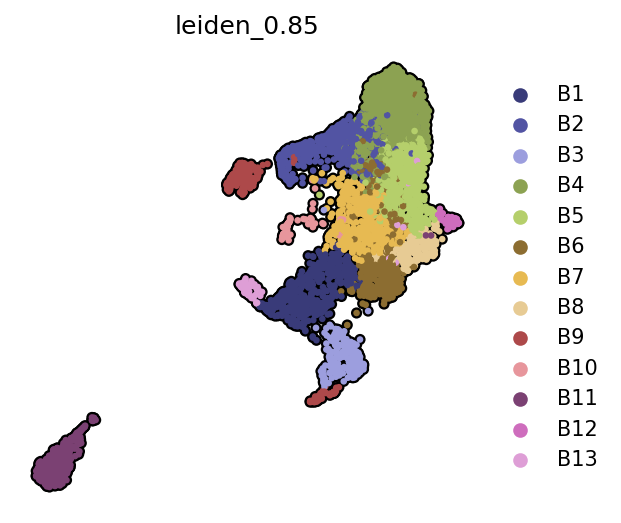

In [31]:
plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = 4, 4

sc.pl.umap(
    adata,
    color='leiden_0.85',
    palette='tab20b',
    size=40,
    ncols=3,
    alpha=1,
    use_raw=False,
    add_outline=True,
    outline_color=('k', 'k'),
    frameon=False,
    wspace=0.5,
)

In [35]:
print(adata.obs['leiden_0.85'].value_counts(sort=False).to_string())
print(adata.obs['leiden_0.85'].value_counts(sort=False,normalize=True).to_string())

leiden_0.85
B1      598
B2      588
B3      307
B4     1175
B5      662
B6      504
B7      553
B8      210
B9      262
B10      71
B11     505
B12      85
B13      88
leiden_0.85
B1     0.106633
B2     0.104850
B3     0.054743
B4     0.209522
B5     0.118046
B6     0.089872
B7     0.098609
B8     0.037447
B9     0.046719
B10    0.012660
B11    0.090050
B12    0.015157
B13    0.015692


In [37]:
sc.tl.rank_genes_groups(
    adata,
    groupby='leiden_0.85',
    method='wilcoxon',
    corr_method='benjamini-hochberg',
    use_raw=False,
    layer='log_norm',
    pts=True,
    key_added='deg_leiden_085',
)

df = sc.get.rank_genes_groups_df(adata, group=None, key='deg_leiden_085')

print(df.shape)
df.head()

(298402, 8)


,group,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference
0,B1,MPO,39.477753,7.091753,0.000000e+00,0.000000e+00,0.998328,0.200000
1,B1,RNASE2,36.608910,5.331764,2.063537e-293,2.368321e-289,0.956522,0.120559
2,B1,LYST,36.297180,3.743008,1.792527e-288,1.371522e-284,0.978261,0.375050
3,B1,LYZ,34.681465,5.475409,1.499397e-263,8.604291e-260,0.929766,0.295409
4,B1,FNDC3B,34.583378,3.332644,4.491718e-262,2.062058e-258,0.979933,0.497405


In [79]:
# drop unnamed genes
df = df[~df['names'].str.startswith('ENSG')]
print(df.shape)

df1 = df[df['pvals_adj'] < 0.05].copy()

n_top = 10

top_scores = (
    df1.groupby('group', group_keys=False)
    .apply(lambda x: x.nlargest(n_top, 'logfoldchanges'))
)

top_scores['rank'] = top_scores.groupby('group')['logfoldchanges'].rank(
    method='first', ascending=False
).astype(int)

table = top_scores.pivot(index='rank', columns='group', values='names')
display(table)

(233012, 8)


/tmp/ipykernel_3318998/1490538066.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.nlargest(n_top, 'logfoldchanges'))


group,B1,B10,B11,B12,B13,B2,B3,B4,B5,B6,B7,B8,B9
rank,,,,,,,,,,,,,
1,SLPI,CLC,LINC00544,CCR9,ACAP3,FCER1A,TOP2A,SELENOM,PRSS2,GINS2,RAB7B,JCHAIN,UBXN10
2,DEFB1,PRG2,VPREB3,CCR7,ANKRD44-IT1,GP1BB,UBE2C,MEG3,SIGLEC17P,FAM111B,IGLL1,CYBB,PLA2G2C
3,PRTN3,EPX,KU-MEL-3,LINC00226,SLC16A4,TIMP3,KIF20A,CLEC3B,TRBC2,TK1,CPA3,IL7R,AHSP
4,ELANE,IL4,DUSP26,KIAA0087,PDE7A,ARHGAP6,DLGAP5,DMKN,BAALC-AS2,UNG,KCNE3,IGHV1-69-2,ST6GALNAC1
5,AZU1,HDC,IGKV2D-26,TNFRSF4,PLCB1,RGS18,PIF1,IQCA1,LINC01819,PCNA,CLEC12A,IGHV3-65,RHAG
6,MNDA,MS4A2,AQP5-AS1,IFNG-AS1,C20orf203,ADRA2A,H3C8,TCEAL2,TRBV12-3,TMSB15A,CDK6-AS1,SPIB,HBA1
7,MPO,RHOXF1P1,CD24,CNTNAP2,INSYN2B,SLC10A5,H2AC14,MEG8,FAM30A,TEDC2,LINC02908,DNTT,APOC1
8,RETN,FAM83F,IGKV2-26,PACSIN1,FAM193B,HBD,AURKB,CXCL8,MMP2,SNAP25,FAM230I,TNNI2,HBA2
9,CSTA,CLEC4OP,ARPP21,IGHV1-24,RGS3,ZNF385D,MKI67,RASSF9,TRBJ2-6,CDC6,LGALS1,SMAD7,NMU


In [81]:
# drop unnamed genes
df = df[~df['names'].str.startswith('ENSG')]
print(df.shape)

n_top = 20

top_scores = (
    df.groupby('group', group_keys=False)
    .apply(lambda x: x.nlargest(n_top, 'scores'))
)

top_scores['rank'] = top_scores.groupby('group')['scores'].rank(
    method='first', ascending=False
).astype(int)

table = top_scores.pivot(index='rank', columns='group', values='names')
display(table)

(233012, 8)


/tmp/ipykernel_3318998/112196744.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.nlargest(n_top, 'scores'))


group,B1,B10,B11,B12,B13,B2,B3,B4,B5,B6,B7,B8,B9
rank,,,,,,,,,,,,,
1,MPO,CLEC4OP,VPREB1,IGHM,PLCB1,ZNF385D,NUSAP1,RPL34,FAM30A,HELLS,GAPDH,ACTG1,S100A6
2,RNASE2,TRD-AS1,CD79B,HOPX,PAN3,PBX1,TUBA1B,CRHBP,TRBC2,TUBA1B,RPLP1,NEGR1,GATA1
3,LYST,SLC24A3,VPREB3,FAM30A,SMYD3,MED12L,TUBB,TPT1,HOPX,PCNA,RPLP0,DNTT,XACT
4,LYZ,IKZF2,DNTT,LST1,RERE,SLC40A1,TOP2A,RPL30,CD52,GINS2,NFIC,TMSB4X,BLVRB
5,FNDC3B,MS4A3,LAPTM5,CLNK,LRBA,ST8SIA6,UBE2C,BST2,SPINK2,STMN1,RPL14,LSP1,CNRIP1
6,SRGN,SRGN,EBF1,MALAT1,CHST11,SERPINB1,HMGB2,RPL35A,PROM1,DUT,HNRNPA1,TMSB10,MIR4435-2HG
7,CALR,XACT,MME,TSC22D1,RUNX1,FCER1A,MKI67,MLLT3,SELL,MCM4,EIF4A1,NREP,RYR3
8,AZU1,CPA3,TOP2B,CNTNAP2,VAV3,TESPA1,BIRC5,RPL13,LINC01819,UNG,RPS16,ADA,S100A4
9,CTSG,SLC45A3,ARPP21,LTB,RNF220,CYTL1,HMGN2,HLA-E,MZB1,MCM3,IGLL1,GPX1,ITGA2B


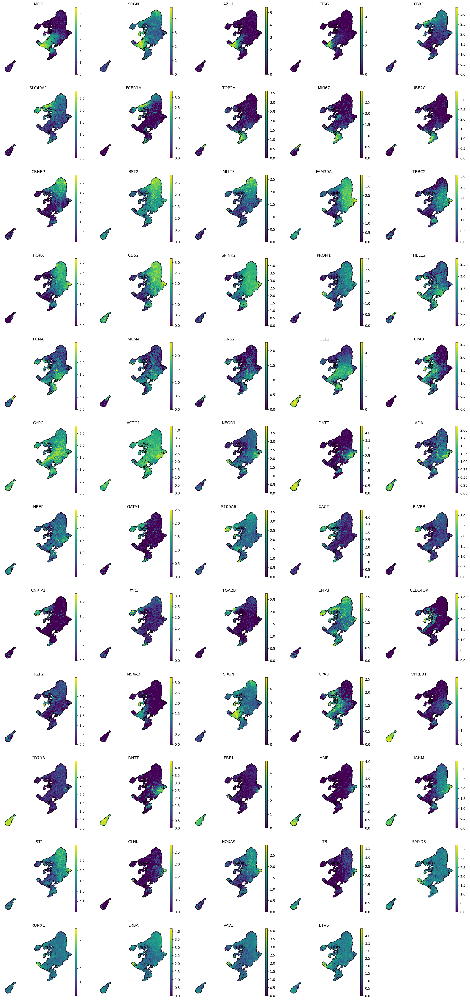

In [87]:
genes_to_plot = [
    'MPO', 'SRGN', 'AZU1', 'CTSG', # B1
    
    'PBX1', 'SLC40A1', 'FCER1A', # B2
    
    'TOP2A', 'MKI67', 'UBE2C', # B3
    
    'CRHBP', 'BST2', 'MLLT3',  # B4
    
    'FAM30A', 'TRBC2', 'HOPX', 'CD52', 'SPINK2', 'PROM1', # B5 ?
    
    'HELLS', 'PCNA', 'MCM4', 'GINS2', # B6

    'IGLL1', 'CPA3', 'GYPC', # B7
    
    'ACTG1', 'NEGR1', 'DNTT', 'ADA', 'NREP', # B8
        
    'GATA1', 'S100A6', 'XACT', 'BLVRB', 'CNRIP1', 'RYR3', 'ITGA2B', 'EMP3', # B9
    
    'CLEC4OP', 'IKZF2', 'MS4A3', 'SRGN', 'CPA3', # B10
    
    'VPREB1', 'CD79B', 'DNTT', 'EBF1', 'MME', # B11
    
    'IGHM', 'LST1', 'CLNK', 'HOXA9', 'LTB', # B12
    
    'SMYD3', 'RUNX1', 'LRBA', 'VAV3', 'ETV6', # B13
    
    # 'MS4A3', 
    # 'VPREB1', # Pre-B cells
    # 'HOPX',
    # 'RUNX1',
    # 'FCER1A',
    # 'CRHBP',    
]

genes_to_plot = [g for g in genes_to_plot if g in adata.var_names]


plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = 4, 4

sc.pl.umap(
    adata,
    color=genes_to_plot,
    size=40,
    ncols=5,
    alpha=1,
    use_raw=False,
    layer='log_norm',
    add_outline=True,
    outline_color=('k', 'k'),
    frameon=False,
    # wspace=0.5,
)

# Marker genes

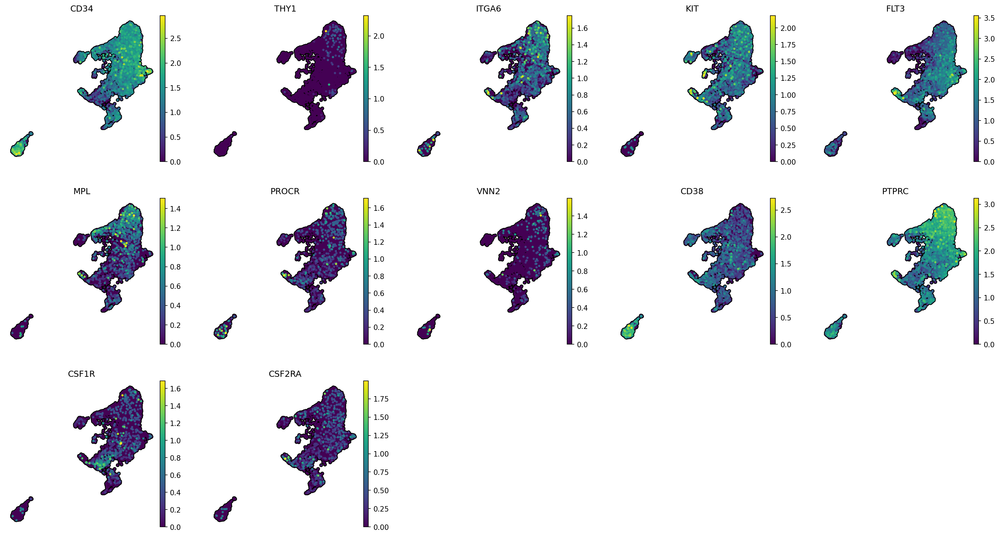

In [5]:
genes_to_plot = [
    # should be positive in HSCs
    'CD34', 'THY1', 'ITGA6', 'KIT', 'FLT3', 'MPL', 'PROCR', 'VNN2', 
    
    # should be negative in HSCs
    'CD38', 'PTPRC', 'CD45RA', 'CD45', 
    'CSF1R', # CD115
    'CSF2RA', # CD116 
]

genes_to_plot = [g for g in genes_to_plot if g in adata.var_names]


plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = 4, 4

sc.pl.umap(
    adata,
    color=genes_to_plot,
    size=40,
    ncols=5,
    alpha=1,
    use_raw=False,
    layer='log_norm',
    add_outline=True,
    outline_color=('k', 'k'),
    frameon=False,
    # wspace=0.5,
)

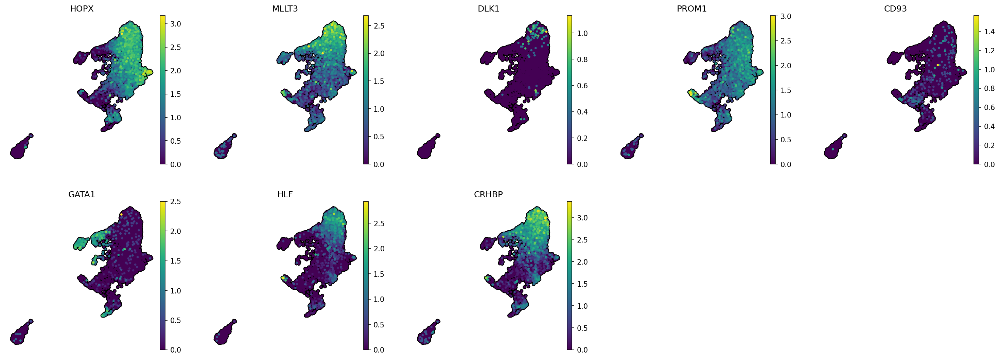

In [88]:
genes_to_plot = [
    'HOPX', 'MLLT3', 'DLK1', 'PROM1', 'CD93', 'KITLG', 
    
    'GATA1', 
    
    'HLF', 'CRHBP', 
    
]

genes_to_plot = [g for g in genes_to_plot if g in adata.var_names]


plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = 4, 4

sc.pl.umap(
    adata,
    color=genes_to_plot,
    size=40,
    ncols=5,
    alpha=1,
    use_raw=False,
    layer='log_norm',
    add_outline=True,
    outline_color=('k', 'k'),
    frameon=False,
    # wspace=0.5,
)

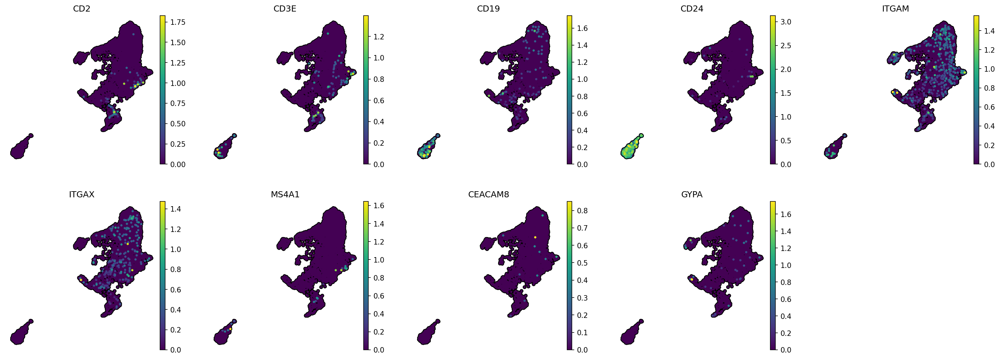

In [15]:
# Lin -
# All HSPC populations should be lin- except for Pro-B progenitor (develops from MLPs or CLPs), and Pre-T (committed T cell progenitor; develops from CLPs or MLPs
genes_to_plot = [
    'CD2', 
    'CD3D', 'CD3E', 'CD3G',
    'CD14',
    'CD19',
    'CD24',
    'ITGAM', # CD11b
    'ITGAX', # CD11c
    'FCGR3A', # CD16
    'MS4A1', # CD20
    'NCAM1', # CD56
    'CEACAM8', # CD66b
    'GYPA', # CD235

]

genes_to_plot = [g for g in genes_to_plot if g in adata.var_names]


plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = 4, 4

sc.pl.umap(
    adata,
    color=genes_to_plot,
    size=40,
    ncols=5,
    alpha=1,
    use_raw=False,
    layer='log_norm',
    add_outline=True,
    outline_color=('k', 'k'),
    frameon=False,
    # wspace=0.5,
)

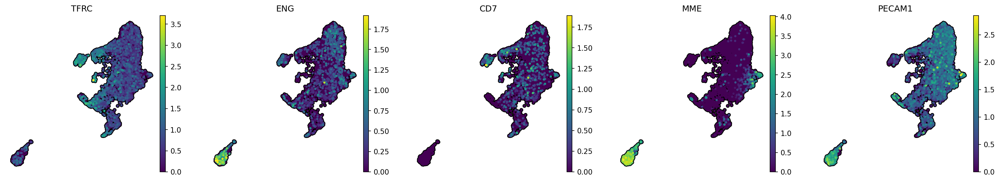

In [67]:
genes_to_plot = [
    'TFRC', # CD71, erythroid/MK identifier
    'ENG', # CD105, erythroid/MK identifier
    'CD7', # lymphoid identifier
    'MME', # CD10, lymphoid identifier
    
    'PECAM1', # CD31

]

genes_to_plot = [g for g in genes_to_plot if g in adata.var_names]


plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = 4, 4

sc.pl.umap(
    adata,
    color=genes_to_plot,
    size=40,
    ncols=5,
    alpha=1,
    use_raw=False,
    layer='log_norm',
    add_outline=True,
    outline_color=('k', 'k'),
    frameon=False,
    # wspace=0.5,
)

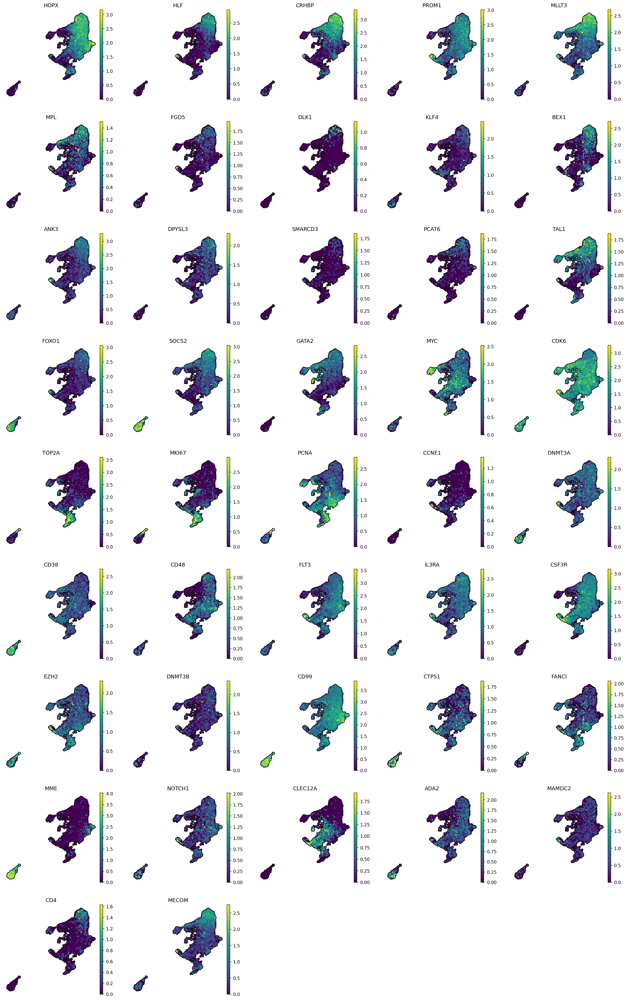

In [103]:
### Genes from Komic et al
genes_to_plot = [
    'HOPX', 'HLF', 'CRHBP', # genes reported as human HSPC markers
    
    'PROM1', 'MLLT3', 'MPL', 'FGD5', 'DLK1', 'KLF4', 'BEX1', # enriched in HSC-1 (as well as the 3 genes above); also showed lowest expression of cell-cycle genes
    'ANK3', 'DPYSL3', 'SMARCD3', 'PCAT6', 'TAL1',
    'FOXO1', 'SOCS2', # + HLF, associated w quiescence 
    'GATA2', 
    
    'MYC', 'CDK6', 'TOP2A', 'MKI67', 'PCNA', 'CCNE1', 'DNMT3A',
    
    'CD38', 'CD48', 'FLT3', 'IL3RA', 'CSF3R', 'EZH2', 'DNMT3B', # high in HSC-2
    'CD99', 'CTPS1', 'FANCI', 'MME', 'NOTCH1', 'CLEC12A', 'ADA2', 'MAMDC2',
    
    'CD4', 'MECOM', # DE (up) in HSC-1 vs HSC-2
]

genes_to_plot = [g for g in genes_to_plot if g in adata.var_names]


plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = 4, 4

sc.pl.umap(
    adata,
    color=genes_to_plot,
    size=40,
    ncols=5,
    alpha=1,
    use_raw=False,
    layer='log_norm',
    add_outline=True,
    outline_color=('k', 'k'),
    frameon=False,
    # wspace=0.5,
)